# BlackLegend — Entregable II (parte 2): reducción de dimensión
**Modelos y Simulación de Sistemas II — Universidad de Antioquia**
Bryan David Molina · David Julian Penagos · Xiomara Giraldo Pérez

Este notebook reproduce la Sección IV del reporte:

1. Análisis individual de variables (correlación, razón discriminante de Fisher, información mutua, AUC univariado) y selección de características.
2. Extracción lineal con **PCA**.
3. Extracción no lineal con **UMAP**.
4. Tabla comparativa final de los dos mejores modelos con cada representación.

**Requisito:** ejecutar antes `02_Modelos_BlackLegend.ipynb`, que guarda en `resultados/` los dos mejores modelos y sus hiperparámetros.
Se usan la misma partición 80/20 y los mismos 10 pliegues de validación (misma semilla), y todas las transformaciones se ajustan solo con los datos de entrenamiento de cada pliegue.

Tiempo de ejecución aproximado: 20–30 minutos (UMAP es la parte más lenta).

In [1]:
import os, json, time, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'      # silencia los avisos de UMAP en los procesos paralelos
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches
from scipy import stats
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import umap

warnings.filterwarnings('ignore')
os.makedirs('figs', exist_ok=True); os.makedirs('resultados', exist_ok=True)

SEMILLA, N_JOBS = 42, 2
COLOR = {'LR': '#2a78d6', 'k-NN': '#eb6834', 'RF': '#1baf7a', 'GB': '#eda100', 'SVM': '#e87ba4', 'MLP': '#6250d6'}
PAGO, INCUMPLE, GRIS = '#2a78d6', '#eb6834', '#52514e'
ESTILO = {'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'font.size': 7.5, 'axes.spines.top': False,
          'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 8,
          'legend.fontsize': 6.5, 'legend.frameon': False, 'lines.linewidth': 1.4}
ANCHO1, ANCHO2 = 3.4, 7.1

def ic95(v):
    v = np.asarray(v, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))

FMT_COMA = matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ','))

## 1. Datos, partición y los dos mejores modelos

In [2]:
df = pd.read_csv('loan_dataset_20000.csv')
y = (1 - df['loan_paid_back']).rename('incumplimiento')      # 1 = incumplió (clase positiva)
nominales = ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose']
redundantes = ['grade_subgrade', 'interest_rate', 'installment']
numericas = [c for c in df.columns if c not in nominales + redundantes + ['monthly_income', 'loan_paid_back']]
X = df[numericas + nominales]
idx_train, idx_test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=SEMILLA)
Xtr, Xte, ytr, yte = X.loc[idx_train], X.loc[idx_test], y.loc[idx_train], y.loc[idx_test]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEMILLA)
PLIEGUES = list(cv.split(Xtr, ytr))

def preprocesador(nums=numericas, noms=nominales):
    partes = []
    if nums: partes.append(('num', StandardScaler(), nums))
    if noms: partes.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), noms))
    return ColumnTransformer(partes)

N_ORIGINAL = preprocesador().fit(Xtr).transform(Xtr[:1]).shape[1]

info = json.load(open('resultados/mejores_modelos.json'))
hiper = json.load(open('resultados/mejores_hiperparametros.json'))
CLASES = {'LR': lambda: LogisticRegression(solver='liblinear', max_iter=2000), 'k-NN': KNeighborsClassifier,
          'RF': lambda: RandomForestClassifier(random_state=SEMILLA, n_jobs=1),
          'GB': lambda: HistGradientBoostingClassifier(random_state=SEMILLA), 'SVM': lambda: SVC(cache_size=1000),
          'MLP': lambda: MLPClassifier(early_stopping=True, n_iter_no_change=10, max_iter=500, random_state=SEMILLA)}

def construir(nombre):
    p = dict(hiper[nombre])
    if 'hidden_layer_sizes' in p: p['hidden_layer_sizes'] = tuple(p['hidden_layer_sizes'])
    return CLASES[nombre]().set_params(**p)

MEJORES = info['dos_mejores']
print('Variables de entrada originales:', N_ORIGINAL)
for m in MEJORES: print(m, hiper[m])

Variables de entrada originales: 37
GB {'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 100}
MLP {'alpha': 1.0, 'hidden_layer_sizes': [64, 32], 'learning_rate_init': 0.001}


## 2. Análisis individual de variables

Se calcula solo con el conjunto de entrenamiento, sobre las 17 variables originales del escenario A:
- **Asociación con la clase:** correlación punto-biserial *r* (numéricas) o *V* de Cramér (categóricas).
- **Razón discriminante de Fisher** (numéricas): $F = (\mu_1 - \mu_0)^2 / (\sigma_1^2 + \sigma_0^2)$.
- **Información mutua** con la clase (capta relaciones no lineales).
- **AUC univariado:** AUC de validación cruzada de una regresión logística entrenada con esa única variable. Un valor de 0,5 significa que la variable sola no discrimina.
- **Importancia por permutación** en el mejor modelo (caída del AUC al barajar la variable): es un control multivariado, porque una variable puede no discriminar sola y sí en interacción con otras.

In [3]:
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = stats.chi2_contingency(t)[0]; n = t.values.sum()
    return np.sqrt(chi2 / (n * (min(t.shape) - 1)))

Xmi = Xtr.copy(); Xmi[nominales] = OrdinalEncoder().fit_transform(Xtr[nominales])
mi = dict(zip(Xmi.columns, mutual_info_classif(Xmi, ytr, discrete_features=[c in nominales for c in Xmi.columns], random_state=SEMILLA)))

filas = []
for c in numericas + nominales:
    es_num = c in numericas
    pre = preprocesador([c], []) if es_num else preprocesador([], [c])
    auc = cross_val_score(make_pipeline(pre, LogisticRegression(max_iter=1000)), Xtr[[c]], ytr, cv=cv, scoring='roc_auc', n_jobs=N_JOBS)
    fila = {'Variable': c, 'Tipo': 'num.' if es_num else 'cat.', 'IM': mi[c], 'AUC univ.': auc.mean(), 'IC AUC': ic95(auc)}
    if es_num:
        x1, x0 = Xtr.loc[ytr == 1, c], Xtr.loc[ytr == 0, c]
        fila['r / V'] = stats.pointbiserialr(ytr, Xtr[c])[0]
        fila['Fisher'] = (x1.mean() - x0.mean()) ** 2 / (x1.var() + x0.var())
    else:
        fila['r / V'] = cramers_v(Xtr[c], ytr)
    filas.append(fila)
individual = pd.DataFrame(filas).set_index('Variable')

# Importancia por permutación del mejor modelo (se ajusta con el 80 % del entrenamiento y se mide en el 20 % restante)
i_a, i_b = train_test_split(np.arange(len(Xtr)), test_size=0.2, stratify=ytr, random_state=SEMILLA)
modelo_ref = Pipeline([('prep', preprocesador()), ('clf', construir(MEJORES[0]))]).fit(Xtr.iloc[i_a], ytr.iloc[i_a])
perm = permutation_importance(modelo_ref, Xtr.iloc[i_b], ytr.iloc[i_b], scoring='roc_auc', n_repeats=20, random_state=SEMILLA, n_jobs=N_JOBS)
individual['Imp. perm.'] = pd.Series(perm.importances_mean, index=Xtr.columns)
individual['DE perm.'] = pd.Series(perm.importances_std, index=Xtr.columns)

# Redundancia entre predictoras numéricas
corr = Xtr[numericas].corr()
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print('Pares de predictoras con |r| > 0,6:'); print(pares[pares.abs() > 0.6].round(2).to_string())

individual = individual.sort_values('AUC univ.', ascending=False)
individual[['Tipo', 'r / V', 'Fisher', 'IM', 'AUC univ.', 'IC AUC', 'Imp. perm.', 'DE perm.']].round(4)

Pares de predictoras con |r| > 0,6:
annual_income        total_credit_limit      0.88
                     current_balance         0.65
total_credit_limit   current_balance         0.73
delinquency_history  num_of_delinquencies    0.90


,Tipo,r / V,Fisher,IM,AUC univ.,IC AUC,Imp. perm.,DE perm.
Variable,,,,,,,,
employment_status,cat.,0.5848,NaN,0.1409,0.7687,0.0059,0.2234,0.0072
debt_to_income_ratio,num.,0.2239,0.1556,0.0250,0.6590,0.0083,0.1124,0.0098
credit_score,num.,-0.2005,0.1383,0.0192,0.6460,0.0111,0.1161,0.0067
delinquency_history,num.,0.0899,0.0243,0.0058,0.5608,0.0097,0.0000,0.0001
num_of_delinquencies,num.,0.0750,0.0172,0.0047,0.5514,0.0092,-0.0001,0.0001
loan_purpose,cat.,0.0318,NaN,0.0005,0.5141,0.0083,0.0003,0.0002
education_level,cat.,0.0228,NaN,0.0003,0.5109,0.0049,-0.0014,0.0005
age,num.,-0.0105,0.0003,0.0000,0.5077,0.0109,0.0003,0.0004
current_balance,num.,0.0096,0.0003,0.0000,0.5060,0.0072,0.0006,0.0006


**Criterio de eliminación.** Una variable es candidata a ser eliminada si cumple las dos condiciones: (i) su AUC univariado es menor que 0,55 (casi no discrimina sola) y (ii) su importancia por permutación en el mejor modelo es menor que 0,005 (tampoco aporta en combinación con las demás; por debajo de ese valor la caída del AUC no se distingue del ruido de la permutación). Además, de cada par de predictoras con |r| > 0,85 se conserva solo la de mayor AUC univariado.

In [4]:
conservar = individual[(individual['AUC univ.'] >= 0.55) | (individual['Imp. perm.'] >= 0.005)].index.tolist()
for (a, b), r in pares[pares.abs() > 0.85].items():
    if a in conservar and b in conservar:
        peor = a if individual.loc[a, 'AUC univ.'] < individual.loc[b, 'AUC univ.'] else b
        conservar.remove(peor); print(f'Par redundante {a} – {b} (r = {r:.2f}): se elimina {peor}')
individual['Decisión'] = ['conservar' if v in conservar else 'eliminar' for v in individual.index]
individual.to_csv('resultados/analisis_individual.csv')
sel_num = [c for c in numericas if c in conservar]; sel_nom = [c for c in nominales if c in conservar]
N_SEL = preprocesador(sel_num, sel_nom).fit(Xtr).transform(Xtr[:1]).shape[1]
print(f'\nSe conservan {len(conservar)} de {len(individual)} variables originales: {conservar}')
print(f'Columnas después de la codificación: {N_SEL} de {N_ORIGINAL} ({1 - N_SEL / N_ORIGINAL:.0%} de reducción)')

Par redundante delinquency_history – num_of_delinquencies (r = 0.90): se elimina num_of_delinquencies

Se conservan 4 de 17 variables originales: ['employment_status', 'debt_to_income_ratio', 'credit_score', 'delinquency_history']
Columnas después de la codificación: 8 de 37 (78% de reducción)


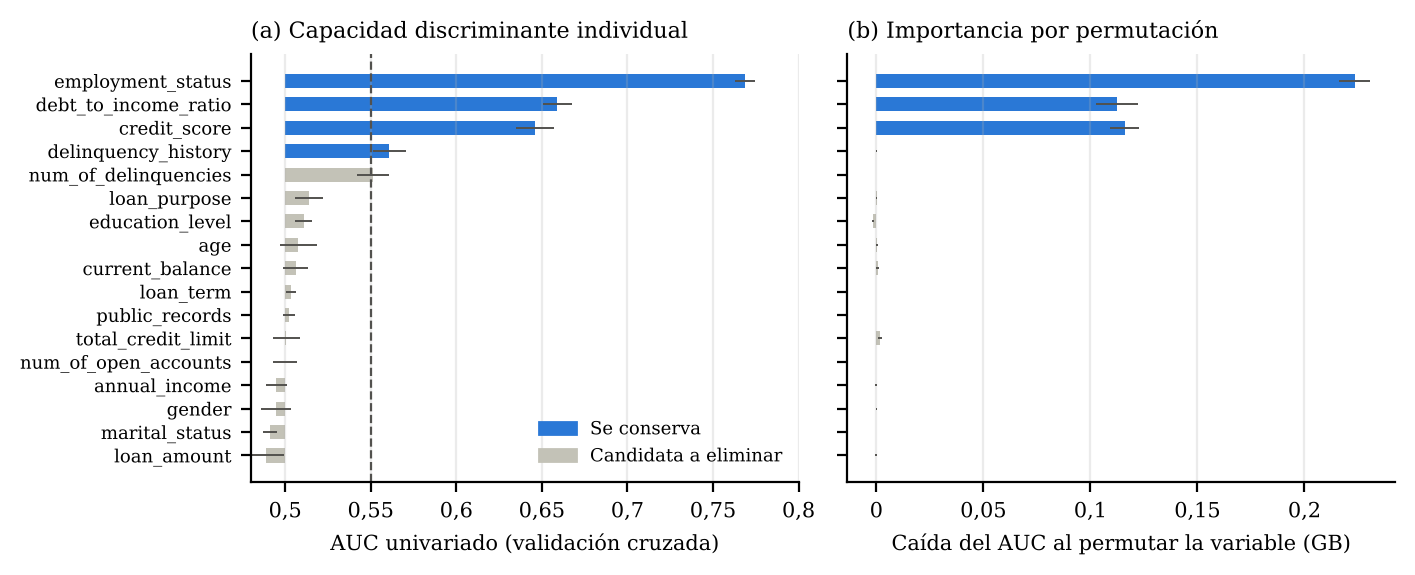

In [5]:
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 2, figsize=(ANCHO2, 2.9), sharey=True)
    d = individual.sort_values('AUC univ.')
    col = [PAGO if v == 'conservar' else '#c3c2b7' for v in d['Decisión']]
    axes[0].barh(d.index, d['AUC univ.'] - 0.5, left=0.5, xerr=d['IC AUC'], color=col, height=0.6, error_kw={'lw': 0.7, 'ecolor': GRIS})
    axes[0].axvline(0.55, color=GRIS, ls='--', lw=0.8); axes[0].set_xlim(0.48, 0.8)
    axes[0].set_xlabel('AUC univariado (validación cruzada)'); axes[0].set_title('(a) Capacidad discriminante individual', loc='left')
    axes[1].barh(d.index, d['Imp. perm.'], xerr=d['DE perm.'], color=col, height=0.6, error_kw={'lw': 0.7, 'ecolor': GRIS})
    axes[1].set_xlabel(f'Caída del AUC al permutar la variable ({MEJORES[0]})'); axes[1].set_title('(b) Importancia por permutación', loc='left')
    for ax in axes: ax.grid(axis='y', visible=False); ax.tick_params(axis='y', labelsize=6.5); ax.xaxis.set_major_formatter(FMT_COMA)
    axes[0].legend(handles=[matplotlib.patches.Patch(color=PAGO, label='Se conserva'), matplotlib.patches.Patch(color='#c3c2b7', label='Candidata a eliminar')], loc='lower right')
    fig.tight_layout(); fig.savefig('figs/fig7_analisis_individual.png', dpi=300, bbox_inches='tight'); plt.show()

## 3. Función de evaluación común

Para cada representación (original, selección, PCA, UMAP) y cada uno de los dos mejores modelos:
- AUC de **validación** en los mismos 10 pliegues, con IC del 95 %. El reductor se ajusta dentro de cada pliegue, solo con la parte de entrenamiento.
- **Umbral** de decisión: índice de Youden sobre las predicciones fuera de pliegue de la primera repetición.
- Reajuste con todo el entrenamiento y evaluación en **entrenamiento** y **prueba** (IC por *bootstrap*).

Los hiperparámetros de los modelos se mantienen fijos en los valores óptimos encontrados con las 37 variables.

In [6]:
def puntaje(m, Z):
    return m.predict_proba(Z)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(Z)

def _pliegue(fabrica, tr, va):
    red = fabrica().fit(Xtr.iloc[tr])      # sin la etiqueta: si se le pasa y, UMAP se vuelve supervisado
    Ztr, Zva = red.transform(Xtr.iloc[tr]), red.transform(Xtr.iloc[va])
    return {m: puntaje(construir(m).fit(Ztr, ytr.iloc[tr]), Zva) for m in MEJORES}

def metricas_umbral(y_real, s, u):
    tn, fp, fn, tp = confusion_matrix(y_real, (s >= u).astype(int)).ravel()
    sens, esp = tp / (tp + fn), tn / (tn + fp); prec = tp / (tp + fp) if tp + fp else 0.0
    return {'Sens.': sens, 'Espec.': esp, 'Prec.': prec, 'F1': 2 * prec * sens / (prec + sens) if prec + sens else 0.0}

def evaluar(nombre, fabrica, completo=True):
    """fabrica() devuelve un transformador sin ajustar (preprocesamiento + reducción)."""
    t0 = time.time()
    salidas = Parallel(n_jobs=N_JOBS)(delayed(_pliegue)(fabrica, tr, va) for tr, va in PLIEGUES)
    filas = []
    for m in MEJORES:
        aucs = np.array([roc_auc_score(ytr.iloc[va], s[m]) for (_, va), s in zip(PLIEGUES, salidas)])
        fila = {'Representación': nombre, 'Modelo': m, 'AUC val.': aucs.mean(), 'IC AUC val.': ic95(aucs)}
        if completo:
            oof = np.empty(len(ytr))
            for (_, va), s in list(zip(PLIEGUES, salidas))[:5]: oof[va] = s[m]
            fpr, tpr, um = roc_curve(ytr, oof); u = um[np.argmax(tpr - fpr)]
            red = fabrica().fit(Xtr); Ztr, Zte = red.transform(Xtr), red.transform(Xte)
            t1 = time.time(); modelo = construir(m).fit(Ztr, ytr); t_fit = time.time() - t1
            s_te = puntaje(modelo, Zte); rng = np.random.default_rng(SEMILLA); yt = yte.values
            boot = [roc_auc_score(yt[i], s_te[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
            fila.update({'Dimensiones': Ztr.shape[1], 'Reducción (%)': 100 * (1 - Ztr.shape[1] / N_ORIGINAL),
                         'AUC entren.': roc_auc_score(ytr, puntaje(modelo, Ztr)), 'AUC prueba': roc_auc_score(yte, s_te),
                         'AUC prueba inf': np.percentile(boot, 2.5), 'AUC prueba sup': np.percentile(boot, 97.5),
                         **{f'{k} prueba': v for k, v in metricas_umbral(yte, s_te, u).items()}, 'Umbral': u,
                         # referencia: qué pasaría con el umbral por defecto de 0,5
                         **{f'{k} prueba (umbral 0,5)': v for k, v in metricas_umbral(yte, s_te, 0.5).items() if k in ('Sens.', 'Espec.')},
                         't ajuste (s)': t_fit})
        filas.append(fila)
    print(f'{nombre:28s} ' + ' | '.join(f"{f['Modelo']}: {f['AUC val.']:.4f} ± {f['IC AUC val.']:.4f}" for f in filas) + f' | {time.time() - t0:.0f} s', flush=True)
    return filas

final = []
final += evaluar('Original', lambda: preprocesador())
final += evaluar('Selección de variables', lambda: preprocesador(sel_num, sel_nom))

Original                     GB: 0.8934 ± 0.0046 | MLP: 0.8884 ± 0.0056 | 12 s


Selección de variables       GB: 0.8934 ± 0.0045 | MLP: 0.8895 ± 0.0053 | 10 s


## 4. Extracción lineal: PCA

PCA se aplica después de estandarizar las numéricas y codificar las nominales. **Criterio para el número de componentes:** el menor número que acumula al menos el **95 % de la varianza**. Como PCA no usa la etiqueta, se complementa con la curva de AUC de validación frente al número de componentes, para verificar si la varianza retenida coincide con la información útil para clasificar.

In [7]:
Z = preprocesador().fit_transform(Xtr)
pca_full = PCA().fit(Z)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
rango_efectivo = int((pca_full.explained_variance_ > 1e-10).sum())
n_var = {p: int(np.searchsorted(var_acum, p) + 1) for p in (0.80, 0.90, 0.95, 0.99)}
print('Rango efectivo de la matriz (37 columnas, 5 dependencias lineales por el One-Hot):', rango_efectivo)
print('Componentes necesarias para acumular 80/90/95/99 % de la varianza:', n_var)
K_PCA = n_var[0.95]

# ¿Las componentes de mayor varianza son las que más discriminan? Correlación de cada componente con la clase
puntajes = pca_full.transform(Z)
r_comp = pd.Series([abs(np.corrcoef(puntajes[:, j], ytr)[0, 1]) for j in range(rango_efectivo)], index=range(1, rango_efectivo + 1))
top = r_comp.sort_values(ascending=False).head(5)
print('\nLas 5 componentes más correlacionadas con el incumplimiento (posición: |r|, % de varianza):')
for j, v in top.items(): print(f'  CP{j}: |r| = {v:.3f}, varianza = {pca_full.explained_variance_ratio_[j - 1]:.1%}')
print(f'Suma de r² de las primeras {K_PCA} componentes: {(r_comp[:K_PCA] ** 2).sum():.3f} | de las {rango_efectivo - K_PCA} restantes: {(r_comp[K_PCA:] ** 2).sum():.3f}')
pd.DataFrame({'componente': r_comp.index, 'abs_r_con_clase': r_comp.values, 'varianza': pca_full.explained_variance_ratio_[:rango_efectivo]}).to_csv('resultados/pca_componentes.csv', index=False)

Rango efectivo de la matriz (37 columnas, 5 dependencias lineales por el One-Hot): 32
Componentes necesarias para acumular 80/90/95/99 % de la varianza: {0.8: 11, 0.9: 15, 0.95: 21, 0.99: 28}

Las 5 componentes más correlacionadas con el incumplimiento (posición: |r|, % de varianza):
  CP18: |r| = 0.397, varianza = 0.8%
  CP14: |r| = 0.268, varianza = 2.0%
  CP9: |r| = 0.249, varianza = 5.8%
  CP26: |r| = 0.217, varianza = 0.5%
  CP29: |r| = 0.168, varianza = 0.3%
Suma de r² de las primeras 21 componentes: 0.347 | de las 11 restantes: 0.077


In [8]:
ks_pca = sorted(set([2, 5, 10, 15, 20, 25, 28, 30, 32, K_PCA]))
barrido_pca = []
for k in ks_pca:
    barrido_pca += evaluar(f'PCA k={k}', lambda k=k: make_pipeline(preprocesador(), PCA(n_components=k, random_state=SEMILLA)), completo=False)
barrido_pca = pd.DataFrame(barrido_pca); barrido_pca['k'] = barrido_pca['Representación'].str.extract(r'k=(\d+)').astype(int)
barrido_pca['Varianza acum.'] = barrido_pca['k'].map(lambda k: var_acum[k - 1])
barrido_pca.to_csv('resultados/barrido_pca.csv', index=False)

# Criterio complementario (supervisado, por parsimonia): el menor k cuyo AUC medio de validación
# queda dentro del IC del 95 % de la mejor configuración de PCA
def elegir_k(barrido):
    prom = barrido.groupby('k')[['AUC val.', 'IC AUC val.']].mean()
    k_mejor = prom['AUC val.'].idxmax()
    k_elegido = int(prom[prom['AUC val.'] >= prom.loc[k_mejor, 'AUC val.'] - prom.loc[k_mejor, 'IC AUC val.']].index.min())
    return prom, int(k_mejor), k_elegido

base = pd.DataFrame(final).query("Representación == 'Original'").set_index('Modelo')
prom_pca, k_mejor_pca, K_PCA_AUC = elegir_k(barrido_pca)
print(prom_pca.round(4))
print(f'\nk por varianza (95 %): {K_PCA} | mejor k = {k_mejor_pca} | k elegido por parsimonia = {K_PCA_AUC}')
final += evaluar(f'PCA ({K_PCA} comp., 95 % var.)', lambda: make_pipeline(preprocesador(), PCA(n_components=K_PCA, random_state=SEMILLA)))
if K_PCA_AUC != K_PCA:
    final += evaluar(f'PCA ({K_PCA_AUC} comp.)', lambda: make_pipeline(preprocesador(), PCA(n_components=K_PCA_AUC, random_state=SEMILLA)))

PCA k=2                      GB: 0.6078 ± 0.0051 | MLP: 0.5792 ± 0.0067 | 2 s


PCA k=5                      GB: 0.6107 ± 0.0098 | MLP: 0.5807 ± 0.0084 | 3 s


PCA k=10                     GB: 0.7067 ± 0.0067 | MLP: 0.6792 ± 0.0331 | 3 s


PCA k=15                     GB: 0.8632 ± 0.0074 | MLP: 0.7745 ± 0.0244 | 5 s


PCA k=20                     GB: 0.8739 ± 0.0068 | MLP: 0.8616 ± 0.0064 | 6 s


PCA k=21                     GB: 0.8740 ± 0.0068 | MLP: 0.8618 ± 0.0064 | 7 s


... (3 outputs left out)

PCA k=32                     GB: 0.8883 ± 0.0049 | MLP: 0.8872 ± 0.0059 | 6 s


    AUC val.  IC AUC val.
k                        
2     0.5935       0.0059
5     0.5957       0.0091
10    0.6930       0.0199
15    0.8189       0.0159
20    0.8678       0.0066
21    0.8679       0.0066
25    0.8691       0.0068
28    0.8844       0.0063
30    0.8878       0.0055
32    0.8878       0.0054

k por varianza (95 %): 21 | mejor k = 30 | k elegido por parsimonia = 28


PCA (21 comp., 95 % var.)    GB: 0.8740 ± 0.0068 | MLP: 0.8618 ± 0.0064 | 11 s


PCA (28 comp.)               GB: 0.8885 ± 0.0053 | MLP: 0.8803 ± 0.0073 | 13 s


## 5. Extracción no lineal: UMAP

UMAP se ajusta sin usar la etiqueta, con la parte de entrenamiento de cada pliegue, y luego proyecta la parte de validación (`transform`). Se usan `n_neighbors = 15` y `min_dist = 0,1` (valores por defecto) y se barre el número de componentes. **Criterio:** UMAP no tiene un equivalente a la varianza explicada, así que se usa el mismo criterio de parsimonia que complementó a PCA: el menor número de componentes cuyo AUC medio de validación queda dentro del IC del 95 % de la mejor configuración.

In [9]:
def fabrica_umap(k, vecinos=15, seleccion=False):
    prep = (lambda: preprocesador(sel_num, sel_nom)) if seleccion else (lambda: preprocesador())
    return lambda: make_pipeline(prep(), umap.UMAP(n_components=k, n_neighbors=vecinos, min_dist=0.1, random_state=SEMILLA, n_jobs=1))

def barrer_umap(ks, seleccion, etiqueta):
    filas = []
    for k in ks:
        filas += evaluar(f'{etiqueta} k={k}', fabrica_umap(k, seleccion=seleccion), completo=False)
    b = pd.DataFrame(filas); b['k'] = b['Representación'].str.extract(r'k=(\d+)').astype(int)
    prom, k_mejor, k_elegido = elegir_k(b)
    print(prom.round(4)); print(f'Mejor k = {k_mejor}; k elegido por parsimonia = {k_elegido}\n')
    return b, k_mejor, k_elegido

barrido_umap, k_mejor, K_UMAP = barrer_umap([2, 5, 10, 20], False, 'UMAP')
barrido_umap.to_csv('resultados/barrido_umap.csv', index=False)
final += evaluar(f'UMAP ({K_UMAP} comp.)', fabrica_umap(K_UMAP))

UMAP k=2                     GB: 0.6056 ± 0.0047 | MLP: 0.5460 ± 0.0271 | 90 s


UMAP k=5                     GB: 0.6131 ± 0.0081 | MLP: 0.4926 ± 0.0198 | 42 s


UMAP k=10                    GB: 0.6328 ± 0.0114 | MLP: 0.5403 ± 0.0157 | 52 s


UMAP k=20                    GB: 0.6434 ± 0.0137 | MLP: 0.5143 ± 0.0178 | 61 s


    AUC val.  IC AUC val.
k                        
2     0.5758       0.0159
5     0.5529       0.0140
10    0.5866       0.0136
20    0.5789       0.0158
Mejor k = 10; k elegido por parsimonia = 2



UMAP (2 comp.)               GB: 0.6056 ± 0.0047 | MLP: 0.5460 ± 0.0271 | 81 s


In [10]:
# Control: ¿cambia la conclusión con una vecindad más global (n_neighbors = 50)?
control = pd.DataFrame(evaluar(f'UMAP k={K_UMAP}, n_neighbors=50', fabrica_umap(K_UMAP, 50), completo=False))
control.to_csv('resultados/control_umap_vecinos.csv', index=False)

UMAP k=2, n_neighbors=50     GB: 0.6081 ± 0.0084 | MLP: 0.4810 ± 0.0240 | 60 s


### UMAP después de la selección de variables

UMAP construye su grafo de vecinos con distancias euclídeas sobre las 37 columnas. Como la mayoría de las variables no discrimina, esas distancias quedan dominadas por ruido (el mismo problema que limita a k-NN). Para separar el efecto del método del efecto del ruido, se repite el barrido aplicando UMAP solo sobre las variables conservadas en la sección 2.

In [11]:
barrido_umap_sel, k_mejor_sel, K_UMAP_SEL = barrer_umap([2, 3, 5], True, 'Selección + UMAP')
barrido_umap_sel.to_csv('resultados/barrido_umap_seleccion.csv', index=False)
final += evaluar(f'Selección + UMAP ({K_UMAP_SEL} comp.)', fabrica_umap(K_UMAP_SEL, seleccion=True))

Selección + UMAP k=2         GB: 0.8632 ± 0.0067 | MLP: 0.8308 ± 0.0073 | 39 s


Selección + UMAP k=3         GB: 0.8676 ± 0.0056 | MLP: 0.8441 ± 0.0111 | 40 s


Selección + UMAP k=5         GB: 0.8686 ± 0.0072 | MLP: 0.8501 ± 0.0105 | 45 s


   AUC val.  IC AUC val.
k                       
2    0.8470       0.0070
3    0.8559       0.0084
5    0.8593       0.0088
Mejor k = 5; k elegido por parsimonia = 3



Selección + UMAP (3 comp.)   GB: 0.8676 ± 0.0056 | MLP: 0.8441 ± 0.0111 | 63 s


### Curvas de PCA y UMAP (Fig. 8) y proyección en dos dimensiones (Fig. 9)

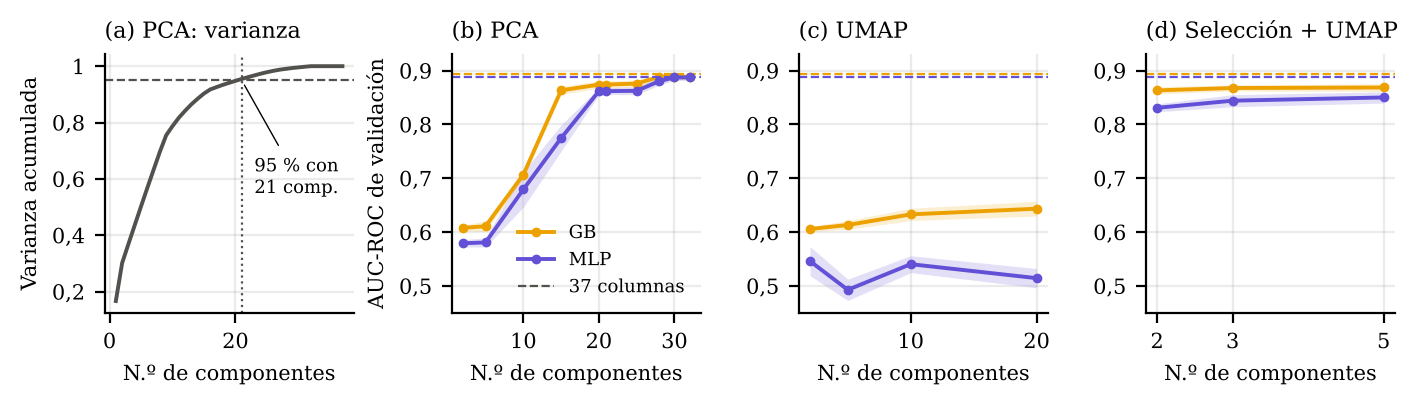

In [12]:
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 4, figsize=(ANCHO2, 2.05))
    ax = axes[0]
    ax.plot(range(1, len(var_acum) + 1), var_acum, color=GRIS)
    ax.axhline(0.95, color=GRIS, ls='--', lw=0.8); ax.axvline(K_PCA, color=GRIS, ls=':', lw=0.8)
    ax.annotate(f'95 % con\n{K_PCA} comp.', (K_PCA, 0.95), xytext=(K_PCA + 2, 0.55), ha='left', fontsize=6.5, arrowprops={'arrowstyle': '-', 'lw': 0.5})
    ax.set_xlabel('N.º de componentes'); ax.set_ylabel('Varianza acumulada'); ax.set_title('(a) PCA: varianza', loc='left')
    for ax, barrido, titulo in [(axes[1], barrido_pca, '(b) PCA'), (axes[2], barrido_umap, '(c) UMAP'), (axes[3], barrido_umap_sel, '(d) Selección + UMAP')]:
        for m in MEJORES:
            d = barrido[barrido.Modelo == m].sort_values('k')
            ax.plot(d['k'], d['AUC val.'], '-o', ms=2.5, color=COLOR[m], label=m)
            ax.fill_between(d['k'], d['AUC val.'] - d['IC AUC val.'], d['AUC val.'] + d['IC AUC val.'], color=COLOR[m], alpha=0.18, lw=0)
            ax.axhline(base.loc[m, 'AUC val.'], color=COLOR[m], ls='--', lw=0.8)
        ax.set_xlabel('N.º de componentes'); ax.set_title(titulo, loc='left'); ax.set_ylim(0.45, 0.93)
    axes[1].set_ylabel('AUC-ROC de validación')
    axes[3].set_xticks(sorted(barrido_umap_sel['k'].unique()))
    axes[1].plot([], [], '--', color=GRIS, lw=0.8, label='37 columnas'); axes[1].legend(loc='lower right')
    for ax in axes: ax.yaxis.set_major_formatter(FMT_COMA)
    fig.tight_layout(w_pad=0.6); fig.savefig('figs/fig8_pca_umap.png', dpi=300, bbox_inches='tight'); plt.show()

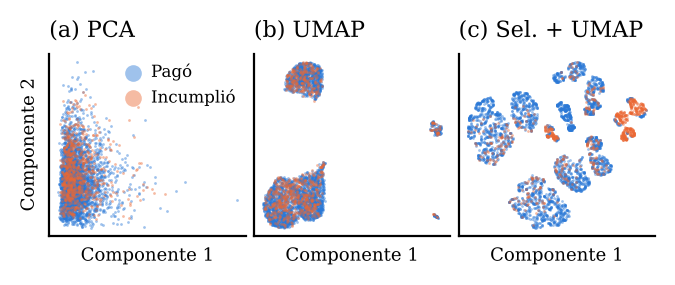

In [13]:
rng = np.random.default_rng(SEMILLA); muestra = rng.choice(len(Xtr), 4000, replace=False)
Z2_pca = make_pipeline(preprocesador(), PCA(2, random_state=SEMILLA)).fit(Xtr).transform(Xtr.iloc[muestra])
Z2_umap = fabrica_umap(2)().fit(Xtr).transform(Xtr.iloc[muestra])
Z2_umap_sel = fabrica_umap(2, seleccion=True)().fit(Xtr).transform(Xtr.iloc[muestra])
with plt.rc_context(ESTILO):
    fig, axes = plt.subplots(1, 3, figsize=(ANCHO1, 1.45))
    for ax, Z2, titulo in [(axes[0], Z2_pca, '(a) PCA'), (axes[1], Z2_umap, '(b) UMAP'), (axes[2], Z2_umap_sel, '(c) Sel. + UMAP')]:
        for clase, nombre, color in [(0, 'Pagó', PAGO), (1, 'Incumplió', INCUMPLE)]:
            mk = ytr.iloc[muestra].values == clase
            ax.scatter(Z2[mk, 0], Z2[mk, 1], s=1.0, color=color, alpha=0.45, label=nombre, rasterized=True, linewidths=0)
        ax.set_xlabel('Componente 1', fontsize=6.5); ax.set_title(titulo, loc='left'); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    axes[0].set_ylabel('Componente 2', fontsize=6.5)
    axes[0].legend(loc='upper right', markerscale=6, handletextpad=0.1, borderpad=0.1, fontsize=6)
    fig.tight_layout(w_pad=0.4); fig.savefig('figs/fig9_proyeccion_2d.png', dpi=300, bbox_inches='tight'); plt.show()

## 6. Tabla comparativa final (Tabla VI del reporte)

In [14]:
final_df = pd.DataFrame(final)
final_df.to_csv('resultados/reduccion_dimension.csv', index=False)
json.dump({'conservar': conservar, 'n_seleccion': N_SEL, 'k_pca_95': K_PCA, 'k_pca_auc': K_PCA_AUC, 'k_umap': K_UMAP, 'k_umap_mejor': int(k_mejor), 'k_umap_sel': K_UMAP_SEL, 'k_umap_sel_mejor': int(k_mejor_sel),
           'varianza': {str(k): float(v) for k, v in zip(range(1, len(var_acum) + 1), var_acum)}, 'n_var': {str(k): v for k, v in n_var.items()},
           'rango_efectivo': rango_efectivo}, open('resultados/reduccion_parametros.json', 'w'), indent=2)
final_df.round(4)

,Representación,Modelo,AUC val.,IC AUC val.,Dimensiones,Reducción (%),AUC entren.,AUC prueba,AUC prueba inf,AUC prueba sup,Sens. prueba,Espec. prueba,Prec. prueba,F1 prueba,Umbral,"Sens. prueba (umbral 0,5)","Espec. prueba (umbral 0,5)",t ajuste (s)
0,Original,GB,0.8934,0.0046,37,0.0000,0.9116,0.8974,0.8853,0.9089,0.7238,0.8684,0.5790,0.6433,0.2004,0.5412,0.9941,0.4100
1,Original,MLP,0.8884,0.0056,37,0.0000,0.8952,0.8904,0.8776,0.9030,0.7362,0.8231,0.5100,0.6026,0.2149,0.5450,0.9909,0.8130
2,Selección de variables,GB,0.8934,0.0045,8,78.3784,0.9046,0.8992,0.8874,0.9106,0.7163,0.8753,0.5895,0.6467,0.2054,0.5375,0.9947,0.2549
3,Selección de variables,MLP,0.8895,0.0053,8,78.3784,0.8939,0.8952,0.8825,0.9071,0.6688,0.9141,0.6605,0.6646,0.2356,0.5350,0.9944,1.3368
4,"PCA (21 comp., 95 % var.)",GB,0.8740,0.0068,21,43.2432,0.9159,0.8793,0.8660,0.8927,0.6738,0.8803,0.5846,0.6260,0.2214,0.4975,0.9972,0.3507
5,"PCA (21 comp., 95 % var.)",MLP,0.8618,0.0064,21,43.2432,0.8751,0.8652,0.8512,0.8783,0.7175,0.8000,0.4728,0.5700,0.1949,0.4550,0.9862,1.4388
6,PCA (28 comp.),GB,0.8885,0.0053,28,24.3243,0.9220,0.8916,0.8793,0.9035,0.7438,0.8288,0.5206,0.6125,0.1924,0.5262,0.9938,0.4060
7,PCA (28 comp.),MLP,0.8803,0.0073,28,24.3243,0.8976,0.8819,0.8690,0.8952,0.7025,0.8453,0.5317,0.6053,0.2194,0.5062,0.9956,1.3309
8,UMAP (2 comp.),GB,0.6056,0.0047,2,94.5946,0.6572,0.5921,0.5690,0.6133,0.6925,0.4472,0.2385,0.3548,0.1886,0.0000,1.0000,0.1084
9,UMAP (2 comp.),MLP,0.5460,0.0271,2,94.5946,0.5375,0.5226,0.5001,0.5456,0.6325,0.4056,0.2101,0.3155,0.2137,0.0000,1.0000,0.3644


## 7. Conclusiones de la reducción de dimensión

- **Selección de variables:** es la única técnica que reduce la dimensión sin perder desempeño; la mayoría de las variables no aporta capacidad discriminante.
- **PCA:** el criterio del 95 % de la varianza descarta componentes de baja varianza que contienen buena parte de la información discriminante. Varianza alta no equivale a capacidad discriminante, porque PCA no usa la etiqueta.
- **UMAP:** sobre las 37 columnas, las distancias quedan dominadas por variables que no discriminan y la proyección pierde casi toda la información útil. Aplicado después de la selección de variables mejora mucho, pero sin superar a la selección sola.